# Day 4 lecture: Text as a feature

<p class="lead">
Period 4 of Day 4, with the Assignment 2 briefing. How free text becomes columns that a regression can use: sentiment scores, keyword flags, length, bag of words and TF-IDF; how to test whether a text feature really improves predictions; and the three traps of feature engineering with text: leakage, features that quietly stand in for something else, and a lexicon that does not speak the domain's language.
</p>

Run each code cell with **Shift + Enter**, in order. The examples use **600 synthetic listings** from a fictional second-hand bicycle marketplace, "CycleSwap", generated in the first cells: each listing has a guide price, whether a shop or a private person is selling, the seller's description, and the price the bike sold for, in **US dollars**. Assignment 2 uses different data (house prices); this lecture deliberately does **not** use its data or generator.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; NLTK reads the VADER lexicon from `data/nltk_data`, so nothing is downloaded.
- **Route A (Try JupyterLab):** upload this notebook, run `%pip install nltk scikit-learn` in a first cell, and replace the setup cell with the NLTK download approach in the [Lab 3 guide](guides/lab3_text_mining.md), Route A.

---

## What you will be able to do

1. Name five ways to turn text into numeric features and say what each one captures.
2. Test whether a text feature improves a regression **on test data**, against a baseline without it.
3. Explain why a general-purpose sentiment lexicon can miss what matters in a specialised domain.
4. Recognise **leakage**: a feature that would not exist at the moment of prediction.
5. Recognise a **proxy**: a text feature whose coefficient really measures something else.
6. Plan Assignment 2: what each part of the analysis is for, and what the report must explain.

This lecture has one period (P4), shared with the Assignment 2 briefing, so it has a **core path** and **extensions**.

| Part | Topic | Path |
|---|---|---|
| 1 | Five ways to turn text into features | Core |
| 2 | A baseline without text | Core |
| 3 | A sentiment score as a feature, and lexicon mismatch | Core |
| 4 | Keyword flags | Core |
| 5 | Length, and features that stand in for something else | Core |
| 6 | Bag of words and TF-IDF | Extension |
| 7 | Leakage | Core |
| 8 | A checklist for text features | Core (summary) |
| 9 | Business case: screening job applications | Extension |
| 10 | Assignment 2 briefing | Core |
| 11 | Practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 5 of the course reading packet for training and test data, error measures, multicollinearity and the question of how a dataset's own construction can make a model look more accurate than it is (its last review question). Chapter 3's account of lexicon-based scoring explains why a domain complaint can come out neutral. This lecture applies both to text used as a predictor.

### Setup

The first cell points NLTK at the course's offline word lists. Run it once at the start of every session. The second loads the other libraries, and the third builds the listings.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
BLUE, ORANGE, GREEN, GREY = "#0072B2", "#D55E00", "#009E73", "#9A9A9A"   # Okabe and Ito colours
vader = SentimentIntensityAnalyzer()

In [3]:
# 600 synthetic listings from a fictional second-hand bicycle marketplace, "CycleSwap"
rng = np.random.default_rng(16)
n = 600
shop = (rng.random(n) < 0.3).astype(int)                                    # 1 = a bike shop is selling
age = rng.integers(1, 9, n)
original = rng.choice([500, 800, 1200, 1800], n, p=[0.3, 0.35, 0.22, 0.13])
book_value = np.round(original * (0.75 - 0.05 * age), -1)                   # guide price for model and age, US dollars
condition = rng.choice(["excellent", "good", "fair", "poor"], n, p=[0.2, 0.4, 0.25, 0.15])
serviced = rng.random(n) < np.where(shop == 1, 0.8, 0.3)
new_tyres = rng.random(n) < 0.25
cmap = lambda d: pd.Series(condition).map(d).values
rust = rng.random(n) < cmap({"excellent": 0.02, "good": 0.08, "fair": 0.4, "poor": 0.7})
scratch = rng.random(n) < cmap({"excellent": 0.02, "good": 0.2, "fair": 0.5, "poor": 0.6})
repair = rng.random(n) < cmap({"excellent": 0.0, "good": 0.02, "fair": 0.25, "poor": 0.6})
noise = rng.normal(0, 40, n)
price = (book_value + cmap({"excellent": 110, "good": 30, "fair": -50, "poor": -150})
         + 35 * serviced + 25 * new_tyres + 60 * shop + noise)
price = np.round(np.maximum(price, 25) / 5) * 5                             # sale price, US dollars

opening = {"excellent": ["Excellent condition, hardly ridden.", "Like new, kept indoors.", "Immaculate bike, barely used."],
           "good": ["Good condition for its age.", "Well looked after.", "Rides well, normal wear."],
           "fair": ["Used but works.", "Some wear and tear.", "Has seen plenty of commuting."],
           "poor": ["Sold as seen.", "Project bike.", "Not ridden for a while."]}
hype = ["Amazing bike!!!", "Great deal, don't miss it!", "Fantastic ride, you will love it!", "Super fun bike, best price around!"]
facts = ["21 speeds.", "Medium frame.", "Aluminium frame.", "Disc brakes.", "Comes with lights and a lock.",
         "Collection only.", "Large frame."]
descriptions = []
for i in range(n):
    parts = [rng.choice(opening[condition[i]])]
    if rust[i]:
        parts.append(rng.choice(["Some rust on the chain.", "Rust spots on the frame.", "Chain is rusty."]))
    if scratch[i]:
        parts.append(rng.choice(["A few scratches on the frame.", "Scratched paintwork.", "Minor scratches."]))
    if repair[i]:
        parts.append(rng.choice(["Needs new brakes.", "Brakes need adjusting.", "Gears slip sometimes."]))
    if serviced[i]:
        parts.append(rng.choice(["Recently serviced.", "Full service last month.", "Serviced by a mechanic."]))
    if new_tyres[i]:
        parts.append(rng.choice(["New tyres fitted.", "Brand new tyres."]))
    parts += list(rng.choice(facts, size=rng.integers(2, 5) if shop[i] else rng.integers(0, 3), replace=False))
    if rng.random() < (0.7 if shop[i] else 0.2):
        parts.append(rng.choice(hype))
    if shop[i]:
        parts.append(rng.choice(["Three-month warranty included.", "Shop warranty included.", "Visit our store for a test ride."]))
    descriptions.append(" ".join(parts))

# The archive stores each listing as it looked when it closed, with the marketplace's status line added
status = np.select([noise < -25, noise > 25], ["SOLD after a price drop.", "SOLD within a day, several offers."], "SOLD.")
listings = pd.DataFrame({"book_value": book_value, "shop": shop, "description": descriptions,
                         "archived_text": [d + " " + s for d, s in zip(descriptions, status)], "price": price})
true_condition = pd.Series(condition, name="true condition")   # known only because the data is synthetic
print(listings.shape)
listings[["book_value", "shop", "description", "price"]].head(6)

(600, 5)


,book_value,shop,description,price
0,280.0,0,Well looked after. Brand new tyres. Aluminium frame.,320.0
1,440.0,0,Good condition for its age. Minor scratches. Brand new tyres. Disc brakes. Collection only.,505.0
2,320.0,1,Some wear and tear. Minor scratches. Recently serviced. Collection only. Disc brakes. Comes with lights an...,285.0
3,840.0,0,Sold as seen. Gears slip sometimes. Aluminium frame. Comes with lights and a lock.,690.0
4,320.0,0,"Rides well, normal wear. Collection only. Comes with lights and a lock. Amazing bike!!!",355.0
5,900.0,1,Sold as seen. Some rust on the chain. Minor scratches. Needs new brakes. Recently serviced. Aluminium fram...,810.0


| Column | Meaning | Units |
|---|---|---|
| `book_value` | Guide price for the bike's model and age, from a price guide | US dollars |
| `shop` | 1 if a bike shop is selling, 0 if a private seller | 0/1 |
| `description` | The seller's text, written when the bike was listed | Text |
| `archived_text` | The listing as stored after it closed, with the marketplace's status line | Text |
| `price` | What the bike sold for (the **target**) | US dollars |

The real condition of each bike is hidden in `true_condition`. A buyer, and our model, only sees what the seller wrote. Can the text tell us what the guide price cannot?

---

## Part 1: Five ways to turn text into features (core)

A regression needs numbers. Each way of turning text into numbers keeps some information and throws the rest away.

| Feature | What it is | Keeps | Loses | Typical use |
|---|---|---|---|---|
| **Sentiment score** | One number, e.g. VADER's compound in −1 to +1 | Overall tone | *What* is good or bad; any domain word the lexicon does not know | Reviews, social media |
| **Keyword flags** | 0/1 columns: does the text mention "rust"? | Specific, chosen facts | Everything you did not think to look for | Known important terms |
| **Length** | Number of words or characters | Effort, detail | Content | Rarely useful alone; often a proxy (Part 5) |
| **Bag of words** | One column per word (or word pair): how often it appears | Which words are used | Word order, meaning | Many-feature models with regularisation |
| **TF-IDF** | Bag of words weighted up for words that are rare across documents | Distinctive words | Order, meaning | Search, classification, the same models |

More advanced methods (word embeddings, large language models) turn text into hundreds of numbers that capture meaning; they are beyond this course, but the traps in this lecture apply to them just as much.

The question for every text feature is the same as for any predictor in the regression lecture: **does it improve predictions on data the model has not seen?**

> **Predict, then run.** The seller's description is mostly about condition. Which do you expect to help the price prediction more: the overall sentiment of the description, or a handful of keyword flags such as "rust" and "serviced"?

---

## Part 2: A baseline without text (core)

Before adding any text feature, fit the model **without** it, on the same training and test split, so that every later model is compared with the same yardstick.

In [4]:
train, test = train_test_split(listings, test_size=0.25, random_state=3)
results = []

def evaluate(cols, label, data_train=None, data_test=None):
    """Fit a linear regression on the training listings and report test errors in US dollars."""
    data_train = train if data_train is None else data_train
    data_test = test if data_test is None else data_test
    model = LinearRegression().fit(data_train[cols], data_train["price"])
    pred = model.predict(data_test[cols])
    row = {"model": label, "test R2": r2_score(data_test["price"], pred),
           "test RMSE ($)": np.sqrt(mean_squared_error(data_test["price"], pred)),
           "test MAE ($)": mean_absolute_error(data_test["price"], pred)}
    results.append(row)
    return model, row

def show(row):
    print(f"{row['model']}: test R2 {row['test R2']:.3f}, RMSE ${row['test RMSE ($)']:.1f}, MAE ${row['test MAE ($)']:.1f}")

base_cols = ["book_value", "shop"]
base_model, row = evaluate(base_cols, "Baseline: guide price + shop")
print(pd.Series(base_model.coef_, index=base_cols).round(2))
show(row)

book_value     0.98
shop          72.44
dtype: float64
Baseline: guide price + shop: test R2 0.874, RMSE $93.2, MAE $77.3


The guide price does most of the work (each guide-price dollar goes with about a dollar of sale price), and shop listings sell for more, holding the guide price constant. The test RMSE is the number to beat: the typical miss, in dollars, of a model that ignores the text.

---

## Part 3: A sentiment score as a feature, and lexicon mismatch (core)

The simplest text feature is VADER's compound score from Day 3: one number per description.

> **Predict, then run.** Which of these phrases will VADER score as negative: "Needs new brakes.", "Some rust on the chain.", "Project bike.", "Amazing bike!!!"?

In [5]:
for phrase in ["Needs new brakes.", "Some rust on the chain.", "Gears slip sometimes.", "Project bike.",
               "Scratched paintwork.", "Amazing bike!!!", "Great deal, don't miss it!", "Excellent condition, hardly ridden."]:
    print(f"{vader.polarity_scores(phrase)['compound']:+.3f}  {phrase}")

print("\nWords in VADER's lexicon (None = unknown, so it scores 0):")
for word in ["rust", "rusty", "scratched", "needs", "slip", "project", "serviced", "immaculate", "amazing", "excellent"]:
    print(f"  {word:11s} {vader.lexicon.get(word)}")

+0.000  Needs new brakes.
+0.000  Some rust on the chain.
+0.000  Gears slip sometimes.
+0.000  Project bike.
+0.000  Scratched paintwork.
+0.688  Amazing bike!!!
+0.704  Great deal, don't miss it!
+0.572  Excellent condition, hardly ridden.

Words in VADER's lexicon (None = unknown, so it scores 0):
  rust        None
  rusty       None
  scratched   None
  needs       None
  slip        None
  project     None
  serviced    None
  immaculate  None
  amazing     2.8
  excellent   2.7


None of the condition problems registers. VADER was built for social-media opinion, and words like "rust", "scratched", "slip" and "needs" are **facts**, not opinions, so they are not in its lexicon. Meanwhile sales talk ("Amazing bike!!!") scores high whatever the bike is like. This is **lexicon mismatch**: the scorer's vocabulary does not match the domain. Day 3 met the same problem with hotel complaints.

How well does the score track the bike's real condition? Because the data is synthetic, we can check.

In [6]:
listings["sentiment"] = listings["description"].map(lambda t: vader.polarity_scores(t)["compound"])
train, test = train_test_split(listings, test_size=0.25, random_state=3)   # same split, new column

check = (pd.DataFrame({"true condition": true_condition, "sentiment": listings["sentiment"], "shop": listings["shop"]})
         .groupby("true condition")[["sentiment"]].mean()
         .reindex(["excellent", "good", "fair", "poor"]).round(2))
print(check)
print(f"\nAverage sentiment: shop listings {listings.loc[listings.shop == 1, 'sentiment'].mean():.2f}, "
      f"private listings {listings.loc[listings.shop == 0, 'sentiment'].mean():.2f}")
print(f"Distinct sentiment values among {len(listings)} listings: {listings['sentiment'].nunique()}")

_, row = evaluate(base_cols + ["sentiment"], "+ sentiment score")
show(row)

                sentiment
true condition           
excellent            0.52
good                 0.54
fair                 0.30
poor                 0.30

Average sentiment: shop listings 0.67, private listings 0.34
Distinct sentiment values among 600 listings: 30
+ sentiment score: test R2 0.886, RMSE $88.7, MAE $71.9


Three lessons:

1. **The score barely separates good bikes from bad ones.** "Good" listings score about as high as "excellent", and "poor" about the same as "fair".
2. **It mostly measures sales talk**, which shops use far more. So part of what the sentiment coefficient picks up is "a shop wrote this" (Part 5 returns to this).
3. **It still helps a little** on test data, because tone and condition are loosely linked. A small improvement is not proof that the feature measures what its name says.

> **Misconception:** "A positive sentiment score means a better product." It means the text contains more words the lexicon rates as positive. Whether that tracks quality is an empirical question you must check, ideally against an independent measure.

---

## Part 4: Keyword flags (core)

A **keyword flag** is a 0/1 column: does the text contain a word or phrase you chose? It is crude, but every flag is easy to explain, and you can pick the words that matter in the domain. Regular expressions (`re`) let one flag catch several spellings.

> **Predict, then run.** Which flag will have the largest coefficient in dollars, positive or negative?

In [7]:
flags = {
    "kw_like_new": r"like new|immaculate|excellent|hardly ridden|barely used",
    "kw_rust":     r"rust",
    "kw_scratch":  r"scratch",
    "kw_repair":   r"needs new|need adjusting|gears slip",
    "kw_serviced": r"servic",
    "kw_tyres":    r"new tyres",
}
text_lower = listings["description"].str.lower()
for name, pattern in flags.items():
    listings[name] = text_lower.str.contains(pattern, regex=True).astype(int)
train, test = train_test_split(listings, test_size=0.25, random_state=3)

print("Share of listings with each flag:")
print(listings[list(flags)].mean().round(2))

flag_model, row = evaluate(base_cols + list(flags), "+ keyword flags")
print("\nCoefficients (US dollars, holding the other columns constant):")
print(pd.Series(flag_model.coef_, index=base_cols + list(flags)).round(1))
show(row)

Share of listings with each flag:
kw_like_new    0.19
kw_rust        0.21
kw_scratch     0.32
kw_repair      0.16
kw_serviced    0.44
kw_tyres       0.25
dtype: float64

Coefficients (US dollars, holding the other columns constant):
book_value       1.0
shop            61.9
kw_like_new    105.2
kw_rust        -63.7
kw_scratch     -23.0
kw_repair      -63.8
kw_serviced     32.1
kw_tyres        15.9
dtype: float64
+ keyword flags: test R2 0.948, RMSE $59.7, MAE $47.5


Six flags cut the test error far more than the sentiment score did, and each coefficient reads as a business sentence: "listings that mention rust sell for about $60 less than similar listings that do not, at the same guide price and seller type". The flags work because they measure **facts about condition**, which is what moves the price.

Two cautions:

- The flags were chosen **by reading the data**. On real data, choose them from domain knowledge or from the **training** listings only, then test once; otherwise the test score flatters you.
- A flag counts a mention, not a meaning: "no rust at all" would trip `kw_rust`. Check a sample of flagged texts by eye.

---

## Part 5: Length, and features that stand in for something else (core)

Does a longer description sell a bike for more?

> **Predict, then run.** Fit price on guide price and the **number of words** in the description, first without the `shop` column, then with it. Will the coefficient on words keep its sign?

In [8]:
listings["words"] = listings["description"].str.split().str.len()
train, test = train_test_split(listings, test_size=0.25, random_state=3)
print(f"Average words: shop listings {listings.loc[listings.shop == 1, 'words'].mean():.1f}, "
      f"private {listings.loc[listings.shop == 0, 'words'].mean():.1f}")

for cols in (["book_value", "words"], ["book_value", "words", "shop"],
             ["book_value", "sentiment"], ["book_value", "sentiment", "shop"]):
    m = LinearRegression().fit(train[cols], train["price"])
    coefs = ", ".join(f"{c} {v:+.1f}" for c, v in zip(cols, m.coef_) if c != "book_value")
    print(f"price ~ {' + '.join(cols):30s} -> {coefs}")

Average words: shop listings 26.0, private 11.6
price ~ book_value + words             -> words +1.4
price ~ book_value + words + shop      -> words -4.4, shop +135.3
price ~ book_value + sentiment         -> sentiment +117.3
price ~ book_value + sentiment + shop  -> sentiment +93.5, shop +39.1


Without `shop`, each extra word goes with a slightly **higher** price; with `shop`, the sign **flips**. Length was standing in for **who wrote the text**: shops write longer listings and charge more. The sentiment coefficient also shrinks once `shop` is in the model, for the same reason.

A text feature is a **proxy** when its coefficient really measures something else that it happens to correlate with: the seller, the product category, the price tier, the writer's age or language. This is the regression lecture's confounding problem (Part 12) in a new form, and it has a practical consequence:

> "Write longer descriptions and you will sell for more" does not follow. Neither does "write more positive descriptions". The model compares listings; it did not watch anyone rewrite one.

For **prediction**, a proxy can still be useful, as long as the link it relies on stays the same. For **explanation** or **advice**, you must ask what the feature really measures.

> **Check your understanding.** In a model of restaurant revenue from online reviews, the number of reviews has a large positive coefficient. Name two things it could be a proxy for.

---

## Part 6: Bag of words and TF-IDF (extension)

Instead of choosing keywords, let the data choose. A **bag of words** makes one column per word (or pair of words, a bigram) and counts how often each appears in each text. With a few hundred listings and a few hundred columns, an ordinary regression would overfit badly, so we use **ridge regression**, which shrinks coefficients towards zero (the regularisation mentioned in the regression lecture, Part 10).

Two rules that prevent leakage between training and test:

1. **Fit the vectoriser on the training texts only** (`fit_transform` on train, `transform` on test). Otherwise the vocabulary and the IDF weights are learned partly from the test set.
2. **Choose the amount of shrinkage** (`alpha`) without looking at the test set: by cross-validation on the training data, or fixed in advance as here.

In [9]:
def text_model(vectoriser, text_col="description", alpha=1.0):
    """Ridge regression on scaled structured columns plus the vectorised text."""
    X_text_train = vectoriser.fit_transform(train[text_col])      # learn the vocabulary on training texts only
    X_text_test = vectoriser.transform(test[text_col])
    scale = np.array([1000.0, 1.0])                               # put book_value on a similar scale to the 0/1 columns
    X_train = sp.hstack([sp.csr_matrix(train[base_cols].values / scale), X_text_train]).tocsr()
    X_test = sp.hstack([sp.csr_matrix(test[base_cols].values / scale), X_text_test]).tocsr()
    model = Ridge(alpha=alpha).fit(X_train, train["price"])
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    return model, vectoriser, {
        "columns": X_train.shape[1],
        "train RMSE ($)": np.sqrt(mean_squared_error(train["price"], pred_train)),
        "test RMSE ($)": np.sqrt(mean_squared_error(test["price"], pred_test)),
        "test R2": r2_score(test["price"], pred_test),
        "test MAE ($)": mean_absolute_error(test["price"], pred_test)}

bow_model, bow_vec, bow_row = text_model(CountVectorizer(min_df=3))                         # single words
_, _, pairs_row = text_model(CountVectorizer(ngram_range=(1, 2), min_df=3))                  # words and word pairs
_, _, tfidf_row = text_model(TfidfVectorizer(min_df=3))
print(pd.DataFrame([bow_row, pairs_row, tfidf_row],
                   index=["Bag of words: words", "Bag of words: words + pairs", "TF-IDF: words"]).round(3))
results.append({"model": "Bag of words (ridge)", **{k: bow_row[k] for k in ["test R2", "test RMSE ($)", "test MAE ($)"]}})

words_coef = pd.Series(bow_model.coef_[len(base_cols):], index=bow_vec.get_feature_names_out())
print("\nWords that push the price down most (US dollars per mention):")
print(words_coef.sort_values().head(8).round(1).to_string())
print("\n... and up most:")
print(words_coef.sort_values().tail(8).round(1).to_string())

                             columns  train RMSE ($)  test RMSE ($)  test R2  test MAE ($)
Bag of words: words              106          38.221         40.575    0.976        33.139
Bag of words: words + pairs      404          29.298         48.543    0.966        37.604
TF-IDF: words                    106          44.022         45.749    0.970        37.490

Words that push the price down most (US dollars per mention):
project   -85.1
while     -40.7
not       -40.7
sold      -32.3
as        -32.3
seen      -29.2
needs     -24.4
works     -22.6

... and up most:
like          41.7
indoors       41.7
kept          41.7
hardly        45.1
excellent     45.1
condition     53.8
immaculate    57.8
barely        57.8


The single-word bag of words beats the hand-picked flags on test data: it found signals we did not choose, such as the opening phrases that hint at condition ("project", "sold as seen", "not ridden for a while", "immaculate", "kept indoors"). Its strongest words are ones a bike mechanic would recognise, which is reassuring. But:

- Adding **word pairs** quadrupled the columns and made the test error **worse**, with a bigger gap between training and test error: more columns, more chances to fit noise. Many pairs also join the end of one sentence to the start of the next (Day 3's warning about bigrams across boundaries).
- Even with single words it has about a hundred columns; without shrinkage it would overfit.
- Its coefficients are **harder to explain** to a manager than six flags, and correlated words share credit unpredictably (multicollinearity again).
- With few texts, or texts written from a few templates (as here), it can latch on to the template wording rather than the meaning, and it would break if sellers started writing differently.

**TF-IDF** gives similar results here. It matters more for long, varied documents, where common words would otherwise dominate.

> **Misconception:** "More features from the text always help." Every column is another chance to fit noise. Compare on test data, prefer the simplest feature set that does nearly as well, and remember that a manager must be able to trust it.

---

## Part 7: Leakage (core)

**Leakage** happens when a feature contains information that would **not be available at the moment the prediction is made**, often because it was recorded after the outcome. The model looks excellent in testing and fails in use.

CycleSwap's data team pulled the texts from the **archive**, which stores each listing as it looked when it **closed**, with the marketplace's status line added at the end.

> **Predict, then run.** We fit the same bag-of-words model on `archived_text` instead of `description`. Will the test RMSE go up or down? Would that model work for a bike listed today?

In [10]:
for text in listings["archived_text"].iloc[:3]:
    print(text)
_, archive_vec, leak_row = text_model(CountVectorizer(min_df=3), text_col="archived_text")
results.append({"model": "Bag of words on archived text (LEAKS)",
                **{k: leak_row[k] for k in ["test R2", "test RMSE ($)", "test MAE ($)"]}})

summary = pd.DataFrame(results).drop_duplicates("model").set_index("model").round(3)
print()
print(summary)

Well looked after. Brand new tyres. Aluminium frame. SOLD.
Good condition for its age. Minor scratches. Brand new tyres. Disc brakes. Collection only. SOLD.
Some wear and tear. Minor scratches. Recently serviced. Collection only. Disc brakes. Comes with lights and a lock. Aluminium frame. Great deal, don't miss it! Shop warranty included. SOLD after a price drop.

                                       test R2  test RMSE ($)  test MAE ($)
model                                                                      
Baseline: guide price + shop             0.874         93.189        77.262
+ sentiment score                        0.886         88.737        71.892
+ keyword flags                          0.948         59.697        47.462
Bag of words (ridge)                     0.976         40.575        33.139
Bag of words on archived text (LEAKS)    0.994         19.617        15.759


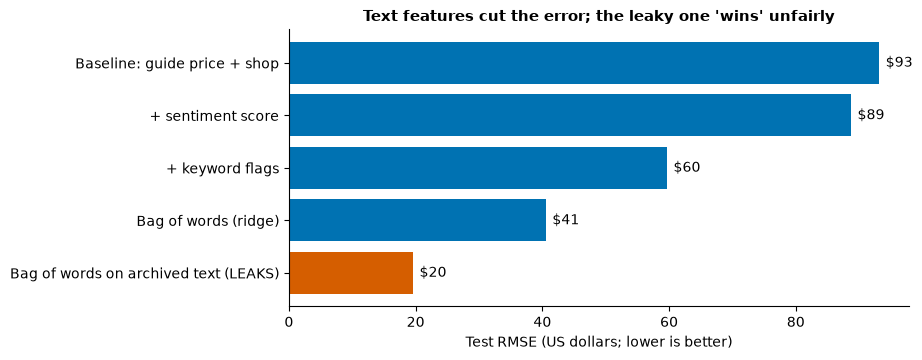

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colours = [ORANGE if "LEAKS" in m else BLUE for m in summary.index]
ax.barh(summary.index[::-1], summary["test RMSE ($)"][::-1], color=colours[::-1])
for y, v in enumerate(summary["test RMSE ($)"][::-1]):
    ax.text(v + 1, y, f"${v:.0f}", va="center")
ax.set_xlabel("Test RMSE (US dollars; lower is better)")
ax.set_title("Text features cut the error; the leaky one 'wins' unfairly")
plt.show()

The archived-text model is the "best" by a clear margin, and it is useless. The status lines "SOLD after a price drop" and "SOLD within a day, several offers" were written **after** the sale and tell the model whether this bike went for more or less than expected. On a bike listed today, that line does not exist.

Common forms of leakage:

| Form | Example |
|---|---|
| Text recorded after the outcome | Status lines, final notes, a support ticket's resolution text |
| A feature computed from the target | "Price per square foot" when predicting price |
| Test data used in preparation | Vocabulary, scaling or keyword choice learned on all rows (Part 6) |
| Duplicates across the split | The same listing posted twice, once in training and once in test |

The defence is a question asked of every feature: **"At the moment we will use this model, would we know this value?"** A test score that looks too good to be true usually is.

**A note on simulated data.** The listings in this lecture are simulated. That is not leakage, because every feature is still known at prediction time, but it does limit what a score can tell you: a model fitted to simulated data learns the rule that made the data.

---

## Part 8: A checklist for text features (core summary)

Before you trust, report or act on a text feature, check:

| Check | Question to ask | In this lecture |
|---|---|---|
| **Improvement** | Does it lower the **test** error compared with the baseline without it? | Parts 2–4, 6 |
| **Validity** | Does it measure what its name says? Compare it with an independent measure, or read a sample by eye | Part 3 |
| **Lexicon fit** | Does the scorer know the domain's words? Look words up in `vader.lexicon` | Part 3 |
| **Variety** | How many distinct values does it take? A score from a few templates is really a category | Part 3 (`nunique`) |
| **Proxy** | Does its coefficient change a lot when you add who wrote it, the product or the region? | Part 5 |
| **Leakage** | Would we know it at the moment of prediction? | Part 7 |
| **Units** | Is the coefficient stated per **one unit** of the feature, and is one unit a sensible step? (A sentiment score runs from −1 to +1, so one unit is half its whole range) | Parts 3–4 |
| **Advice** | Does the business advice follow from a comparison, or does it assume that changing the text changes the outcome? | Part 5 |

---

## Part 9: Business case: screening job applications (extension)

A company receives 5,000 applications a year for graduate roles and wants a model that predicts each applicant's first-year performance rating from the application text (keyword flags and a bag of words), so that recruiters read the top 20% first.

Discussion questions (groups of three, 10 minutes):

1. **Target.** First-year rating is only known for people who were **hired**. What does that do to the training data, and to predictions for the kinds of people the company did not hire in the past?
2. **Proxies.** Which words in an application could stand in for gender, age, nationality or social class (names of clubs, schools, sports, gaps in dates)? A widely reported 2018 case involved a large technology company that dropped an experimental CV-screening model after it learned to penalise words associated with women. How would you test for this before use?
3. **Leakage.** The HR system stores applications **with recruiters' notes added during interviews**. Why must those notes be removed before training?
4. **Lexicon and style.** Applicants who are not native speakers may use fewer of the "confident" words a sentiment lexicon rates highly. What would a sentiment feature do to them?
5. **Decision.** Recommend whether to use the model, and under what safeguards (human review, regular bias audits by group, explaining to applicants, legal review under the laws that apply, such as China's Personal Information Protection Law or the EU's GDPR), using the four parts from Day 3: finding, evidence, action with an owner, and how you would know it worked.

---

## Part 10: Assignment 2 briefing (core)

In Assignment 2 you play the lead data miner at a real-estate analytics firm. GAP gives you the code: it **generates** 500 synthetic house sales (floor area, bedrooms, age, an agent's description and the sale price), draws two exploratory charts, turns each description into a **Text Appeal Score** with VADER, fits a **multiple linear regression** on an 80/20 split, and prints test R², RMSE and the coefficients. You then write a **five-section report** for the firm's board. Weight 6%; due **Sunday 22 November, 23:59 China Standard Time**.

Before you start, read the [Assignment 2 guide](guides/assignment2_predictive_report.md). It has a corrected copy of GAP's code for the offline route, the known problems in GAP's code (one line will not run as printed), and checks you can make without seeing anyone's answers.

How today's lectures map to the report:

| Report section (GAP's headings) | What it asks you to do | Revisit |
|---|---|---|
| Executive Summary | Purpose, structured and unstructured data, the goal of the model | Regression lecture Part 1; this lecture Part 1 |
| Exploratory Data Analysis | Read a scatter plot and a box plot by bedrooms: relationship, medians, spread | Day 1 and Day 2 lectures; regression lecture Part 2 |
| Text Mining Methodology & Value | How text became a number, and why that matters for a pricing model | Day 3 text mining, Part 6; this lecture Parts 1, 3 and 8 |
| Predictive Analytics Results | Test R² and RMSE in plain words; each coefficient in dollars with its holding-constant clause; what one unit of the text score is worth | Regression lecture Parts 3, 5 and 6; this lecture Part 8 ("Units") |
| Strategic Recommendations | Two actionable recommendations to agents | Regression lecture Part 12; this lecture Part 5 ("Advice") |

Questions to ask **your own output** while you write (they have no single right answer here, and this lecture does not answer them):

1. Which sentiment scorer actually ran in your notebook: the real VADER lexicon, or the simple fallback built into GAP's code? Your scores depend on it (the guide shows how to check).
2. How many **distinct** values does your Text Appeal Score take? What does that tell you about how the descriptions were produced?
3. Do the scores agree with how a human would read each description? If one does not, why might that be? (Day 3, Parts 6 and 7; this lecture, Part 3.)
4. Is your test R² high because house prices are easy to predict, or because of how the data was **generated**? (This lecture, Part 7, last row of the table.)
5. When you state a coefficient in dollars, what are you holding constant, and over what range of the data does it hold?
6. Does your recommendation about writing descriptions follow from what the model compares, or does it assume that rewriting a description changes the house? (This lecture, Part 5.)

Write every number **from your own output**, with its unit, and name the table or chart it comes from.

---

## Part 11: Practice, quiz and summary

### Practice

#### Core

**Core 1.** Add a flag `kw_warranty` for "warranty" to the keyword model. Does it improve the test RMSE? What is it a proxy for?

**Core 2.** Score each of your own five bike descriptions with VADER: two that describe a bike in poor condition politely, and three of your choice. Which scores would mislead a pricing model?

**Core 3.** For the keyword model in Part 4, write the `kw_repair` coefficient as a business sentence with units and the holding-constant clause.

#### Stretch

**Stretch 1.** Make a copy of the analyser and add "rust", "rusty", "scratched" and "slip" to its lexicon with negative ratings you can justify. Recompute the sentiment feature and the model. How much closer does it get to the keyword model? Why is tuning a lexicon on the same data you test on risky?

**Stretch 2.** Refit the bag-of-words model with `alpha` = 0.1, 1, 10 and 100. Plot training and test RMSE against `alpha` (log scale). Where is the best balance? Why should you choose `alpha` by cross-validation on the training data rather than from this plot?

**Stretch 3.** Score each **sentence** of a description separately and use the **minimum** sentence score as a feature. Does it beat the whole-text compound score? Why might it?

#### Challenge

**Challenge 1.** Build the keyword list automatically from the **training listings only**: keep the 20 words whose presence is most correlated with the residuals of the baseline model, turn them into flags, and test once. Compare with the hand-picked flags.

**Challenge 2.** Write a function `leak_check(df, text_col, target)` that fits a bag-of-words model and prints the ten words with the largest coefficients, so that a human can spot suspicious ones (status words, dates, prices). Run it on `archived_text`.

**Challenge 3.** Simulate your own small "generated data" trap: make 200 rows where a text label and a price premium are created in the **same** `if` statement, plus noise. Fit a regression with and without the text feature, and explain to a manager why the impressive R² does not mean text predicts prices in real life.

### Quiz

1. Name five ways to turn text into numbers and one weakness of each.
2. Why should every text feature be compared with a baseline model on the **same** test set?
3. Give two reasons a domain complaint can get a sentiment score of 0.
4. What is a keyword flag, and why is it easy to explain to a manager?
5. A text feature's coefficient changes sign when you add the seller type. What does that tell you?
6. Why must a vectoriser be fitted on the training texts only?
7. Define leakage and give one example involving text.
8. "Listings with more positive descriptions sell for more, so sellers should write more positively." What is wrong with this advice?
9. A sentiment score runs from −1 to +1. What does a coefficient of 50 on it mean, and what is a more realistic step to quote?
10. What question should you ask of every feature before you trust a high test score?

### Summary

| Idea | Remember |
|---|---|
| Text features | Sentiment, keyword flags, length, bag of words, TF-IDF: each keeps something and loses something |
| Baseline | Always compare with the same model **without** the text feature, on the same test set |
| Lexicon mismatch | A general lexicon misses domain facts ("rust", "needs") and rewards sales talk |
| Keyword flags | Simple, explainable, often strong; choose them from domain knowledge or training data |
| Proxies | A text feature can stand in for who wrote it; check whether its coefficient survives adding that |
| Bag of words | Many columns: needs regularisation; fit the vectoriser on training data only |
| Leakage | Would we know this value at prediction time? Too good to be true usually is |
| Advice | A coefficient compares cases; it does not show that changing the text changes the outcome |

**References:** Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of the International AAAI Conference on Web and Social Media*, 8(1), 216–225. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1–21. Gentzkow, M., Kelly, B., & Taddy, M. (2019). Text as data. *Journal of Economic Literature*, 57(3), 535–574.

**Next:** the [Assignment 2 guide](guides/assignment2_predictive_report.md). Tomorrow (Day 5): reading a regression for a manager, spreadsheet simulation, and Lab 5.

---

## For the facilitator

This notebook is **period P4** of Day 4, after the regression lecture in P1–P3. Day 4 has no lab, so the Assignment 2 briefing (Part 10) closes the day. One period is not enough for every part, so the core path is about 30 minutes of text features plus 15 minutes of briefing; the extensions suit faster students, the online week, or Day 7's studio periods (support for Assignments 2 and 3). No Assignment 2 answers are given: its generator and data are never run here, and the briefing's questions are left for students to answer from their own output.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P3 (if time) | 0–5 | Part 1 table | Only if the regression lecture finishes early |
| P4 | 3 | Setup cells; the data table | Make sure Route B students' NLTK cell runs |
| P4 | 4 | Part 1: five ways (skip if done in P3) | Ask for the Part 1 prediction by show of hands |
| P4 | 3 | Part 2: baseline | Write the baseline RMSE on the board |
| P4 | 7 | Part 3: sentiment, lexicon look-ups, the condition table | Students predict the four phrases on paper first |
| P4 | 5 | Part 4: keyword flags | Read one coefficient aloud as a sentence |
| P4 | 4 | Part 5: length and the sign flip | Ask "should sellers write more?" |
| P4 | 5 | Part 7: leakage and the comparison chart | Collect the up/down prediction first |
| P4 | 2 | Part 8: checklist | Point at the "Units" and "Advice" rows |
| P4 | 12 | Part 10: Assignment 2 briefing | Walk through the mapping table and the six questions; show the guide page and its pitfalls (the `range` typo, the sentiment fallback) |
| Later | 15 | Part 6: bag of words and TF-IDF | Day 7 studio, faster students, or self-study |
| Later | 10 | Part 9: business case | Good group discussion for the online week |
| Self-study | — | Part 11: practice and quiz | Core items first; Challenge 3 helps with Assignment 2's critical thinking without answering it |

If the regression lecture overruns into P4, cut Part 5 to the printed coefficients and one sentence, and skip Part 8's table (students can read it). Do not cut the briefing.